In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("House Price Analysis - Project 6")

House Price Analysis - Project 6


In [2]:
df = pd.read_csv(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data\house_prices (1).csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (300, 8)


,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000


In [3]:
print("Dataset Information")
print("=" * 40)

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset Information
Shape: (300, 8)

Missing values:
Property_ID      0
Area             0
Bedrooms         0
Bathrooms        0
Age              0
Location         0
Property_Type    0
Price            0
dtype: int64

Duplicate rows: 0

Data types:
Property_ID        str
Area             int64
Bedrooms         int64
Bathrooms        int64
Age              int64
Location           str
Property_Type      str
Price            int64
dtype: object


In [4]:
print("Descriptive Statistics")
print("=" * 40)

df[["Area", "Bedrooms", "Bathrooms", "Age", "Price"]].describe()

Descriptive Statistics


,Area,Bedrooms,Bathrooms,Age,Price
count,300.00000,300.000000,300.000000,300.000000,3.000000e+02
mean,2759.70000,3.033333,2.026667,25.000000,2.488366e+07
std,1297.68143,1.467219,0.792495,14.332646,1.266525e+07
min,520.00000,1.000000,1.000000,0.000000,3.695000e+06
25%,1675.75000,2.000000,1.000000,12.000000,1.527750e+07
50%,2738.00000,3.000000,2.000000,25.500000,2.236500e+07
75%,3801.25000,4.000000,3.000000,36.250000,3.460812e+07
max,4999.00000,5.000000,3.000000,49.000000,5.870000e+07


In [5]:
print("Correlation with House Price")
print("=" * 40)

correlation = df[[
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Age",
    "Price"
]].corr()

print(correlation["Price"].sort_values(ascending=False))

Correlation with House Price
Price        1.000000
Area         0.796287
Bedrooms     0.202458
Bathrooms   -0.030279
Age         -0.130781
Name: Price, dtype: float64


In [6]:
location_analysis = df.groupby("Location").agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Average_Area=("Area", "mean")
).round(2)

location_analysis = location_analysis.sort_values(
    "Average_Price",
    ascending=False
)

location_analysis

,Property_Count,Average_Price,Median_Price,Average_Area
Location,,,,
City Center,97,33149793.81,34970000.0,2777.87
Suburb,105,25108071.43,24030000.0,2764.89
Rural,98,16461428.57,16052500.0,2736.16


In [7]:
property_type_analysis = df.groupby("Property_Type").agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Average_Area=("Area", "mean"),
    Average_Bedrooms=("Bedrooms", "mean")
).round(2)

property_type_analysis = property_type_analysis.sort_values(
    "Average_Price",
    ascending=False
)

property_type_analysis

,Property_Count,Average_Price,Median_Price,Average_Area,Average_Bedrooms
Property_Type,,,,,
Apartment,91,27124203.30,25642500.0,3045.60,3.04
Villa,102,24989852.94,21810000.0,2720.56,3.07
House,107,22876915.89,20575000.0,2553.86,2.99


In [8]:
location_type_analysis = df.groupby(
    ["Location", "Property_Type"]
).agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Average_Area=("Area", "mean")
).round(2)

location_type_analysis

Property_Count  Average_Price  Median_Price  \
Location    Property_Type                                                
City Center Apartment                  28    37481428.57    38865000.0   
            House                      37    28302432.43    25940000.0   
            Villa                      32    34964375.00    35160000.0   
Rural       Apartment                  31    16885000.00    15985000.0   
            House                      34    17378823.53    17455000.0   
            Villa                      33    15118333.33    14770000.0   
Suburb      Apartment                  32    27980859.38    30960000.0   
            House                      36    22493333.33    21386250.0   
            Villa                      37    25167567.57    22807500.0   

                           Average_Area  
Location    Property_Type                
City Center Apartment           3229.93  
            House               2339.97  
            Villa               2888.62  
Rural       Apartment           2819.90  
            House               2865.76  
            Villa               2523.97  
Suburb      Apartment           3102.97  
            House               2479.11  
            Villa               2750.54

In [9]:
df["Price_Segment"] = pd.cut(
    df["Price"],
    bins=[0, 15000000, 30000000, float("inf")],
    labels=["Budget", "Mid-Range", "Premium"]
)

price_segment_analysis = df.groupby(
    "Price_Segment",
    observed=False
).agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Average_Area=("Area", "mean")
).round(2)

price_segment_analysis

,Property_Count,Average_Price,Average_Area
Price_Segment,,,
Budget,75,10736400.00,1279.31
Mid-Range,131,21633435.11,2751.81
Premium,94,40700930.85,3951.86


In [10]:
df["Price_per_Area"] = df["Price"] / df["Area"]

print("Price per Area Analysis")
print("=" * 40)

print(df["Price_per_Area"].describe().round(2))

Price per Area Analysis
count      300.00
mean      9542.84
std       3186.33
min       4555.56
25%       6904.84
50%       9282.16
75%      11526.37
max      21739.59
Name: Price_per_Area, dtype: float64


In [11]:
top_10_expensive = df.sort_values(
    "Price",
    ascending=False
)[[
    "Property_ID",
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Age",
    "Location",
    "Property_Type",
    "Price"
]].head(10)

top_10_expensive

,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
228,PROP0229,4610,5,3,4,City Center,House,58700000
193,PROP0194,4871,4,1,4,City Center,Villa,57310000
283,PROP0284,4746,5,1,22,City Center,Apartment,56260000
212,PROP0213,4488,5,2,10,City Center,House,55880000
35,PROP0036,4919,4,2,45,City Center,Villa,54690000
286,PROP0287,4733,5,1,39,City Center,Apartment,54430000
152,PROP0153,4378,5,3,28,City Center,Villa,53980000
293,PROP0294,4917,2,1,2,City Center,House,53970000
94,PROP0095,4642,4,2,26,City Center,Villa,53820000
12,PROP0013,4522,4,1,12,City Center,Apartment,53020000


In [12]:
best_value_properties = df.sort_values(
    "Price_per_Area",
    ascending=True
)[[
    "Property_ID",
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Age",
    "Location",
    "Property_Type",
    "Price",
    "Price_per_Area"
]].head(10)

best_value_properties

,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price,Price_per_Area
74,PROP0075,1350,1,1,42,Rural,Villa,6150000,4555.555556
279,PROP0280,2795,1,1,39,Rural,Apartment,13525000,4838.998211
167,PROP0168,4875,1,3,49,Rural,House,24425000,5010.256410
244,PROP0245,4079,1,2,36,Rural,Villa,20595000,5049.031625
242,PROP0243,3479,1,1,19,Rural,Villa,17945000,5158.091406
164,PROP0165,3786,1,2,27,Rural,Apartment,19580000,5171.685156
191,PROP0192,1104,1,3,46,Rural,Apartment,5720000,5181.159420
80,PROP0081,3635,1,3,35,Rural,Villa,18925000,5206.327373
266,PROP0267,3457,1,2,24,Rural,Villa,18085000,5231.414521
199,PROP0200,3091,2,2,45,Rural,House,16205000,5242.639922


In [13]:
bedroom_analysis = df.groupby("Bedrooms").agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Average_Area=("Area", "mean")
).round(2)

bedroom_analysis

,Property_Count,Average_Price,Median_Price,Average_Area
Bedrooms,,,,
1,70,22514571.43,19360000.0,2845.80
2,46,23198586.96,20967500.0,2782.24
3,49,20912295.92,18840000.0,2555.35
4,74,27048209.46,24562500.0,2694.96
5,61,29437254.10,27445000.0,2886.59


In [14]:
age_analysis = df.groupby("Age").agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Average_Area=("Area", "mean")
).round(2)

age_analysis

,Property_Count,Average_Price,Median_Price,Average_Area
Age,,,,
0,2,27322500.00,27322500.0,2943.00
1,6,31245416.67,33690000.0,3166.83
2,6,30332500.00,33045000.0,3093.33
3,6,32914166.67,37680000.0,3177.00
4,6,33995000.00,32407500.0,3094.50
5,5,25359000.00,20165000.0,2931.20
6,10,15202500.00,12731250.0,1652.00
7,6,24153333.33,23800000.0,2423.17
8,10,28871500.00,32531250.0,3378.00


In [15]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[-1, 10, 25, 40, 49],
    labels=["New", "Mid-Age", "Old", "Very Old"]
)

age_group_analysis = df.groupby(
    "Age_Group",
    observed=False
).agg(
    Property_Count=("Property_ID", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Average_Area=("Area", "mean")
).round(2)

age_group_analysis

,Property_Count,Average_Price,Median_Price,Average_Area
Age_Group,,,,
New,67,26942462.69,24790000.0,2923.24
Mid-Age,83,25934759.04,24030000.0,2859.94
Old,95,23628026.32,20242500.0,2604.28
Very Old,55,22958272.73,19597500.0,2677.65


In [16]:
print("Final Dataset Structure")
print("=" * 40)

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
df.head()

Final Dataset Structure
Shape: (300, 11)

Columns:
['Property_ID', 'Area', 'Bedrooms', 'Bathrooms', 'Age', 'Location', 'Property_Type', 'Price', 'Price_Segment', 'Price_per_Area', 'Age_Group']

First 5 rows:


,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price,Price_Segment,Price_per_Area,Age_Group
0,PROP0001,3712,4,3,36,Rural,House,22260000,Mid-Range,5996.767241,Old
1,PROP0002,1591,4,1,35,Suburb,House,16057500,Mid-Range,10092.708988,Old
2,PROP0003,1646,4,3,20,Rural,Villa,12730000,Budget,7733.900365,Mid-Age
3,PROP0004,4814,1,2,13,City Center,Villa,50840000,Premium,10560.864146,Mid-Age
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000,Budget,13312.500000,Old


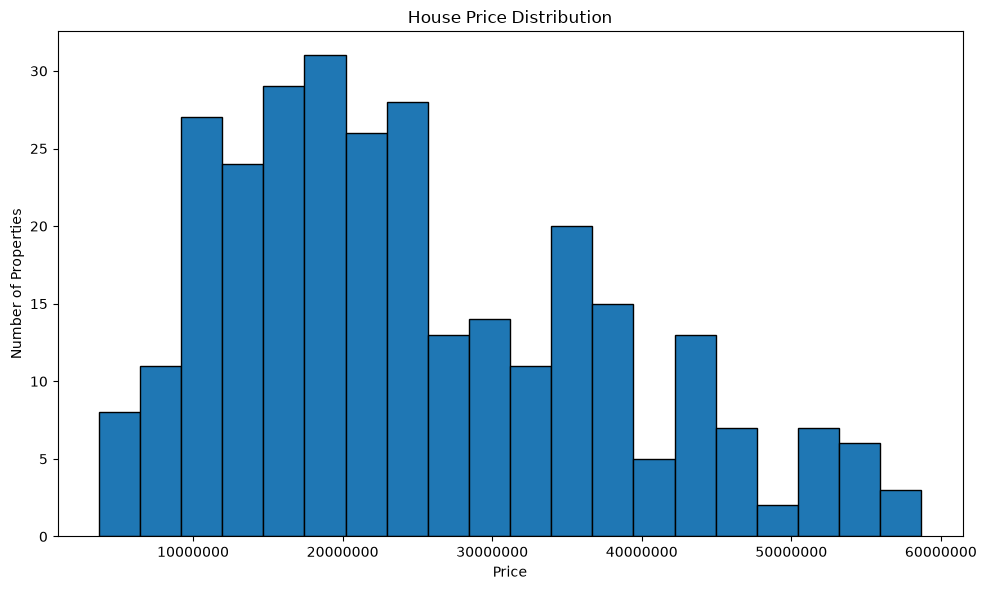

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(df["Price"], bins=20, edgecolor="black")

plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\house_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

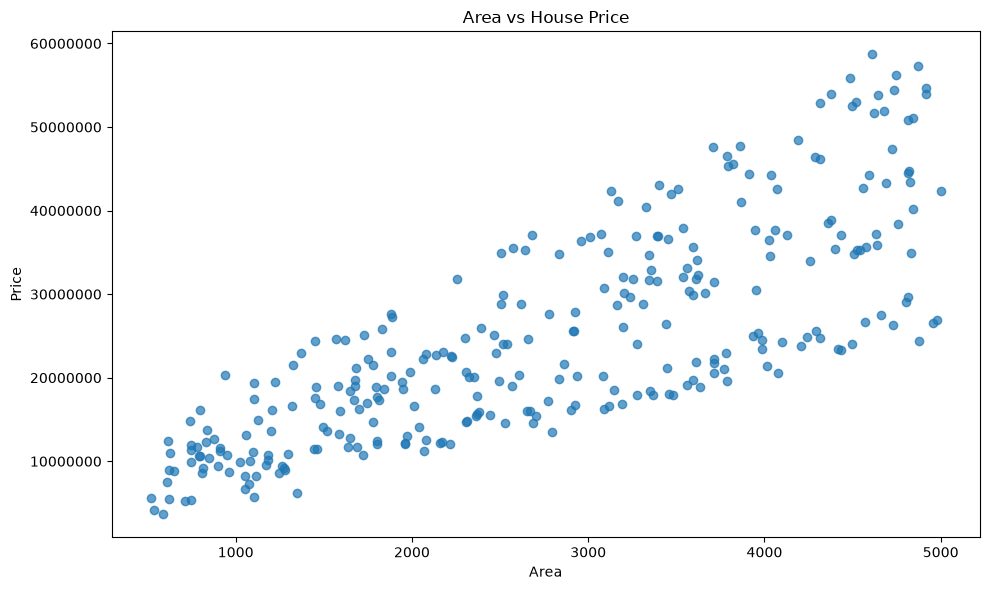

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Area"],
    df["Price"],
    alpha=0.7
)

plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\area_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

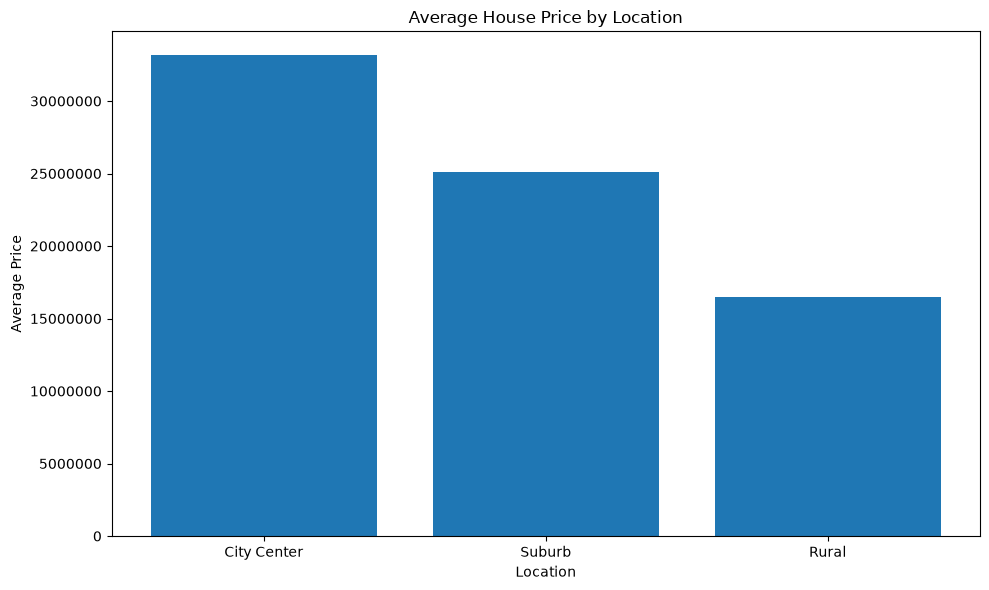

In [19]:
location_price = df.groupby("Location")["Price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

plt.bar(
    location_price.index,
    location_price.values
)

plt.title("Average House Price by Location")
plt.xlabel("Location")
plt.ylabel("Average Price")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\average_price_by_location.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

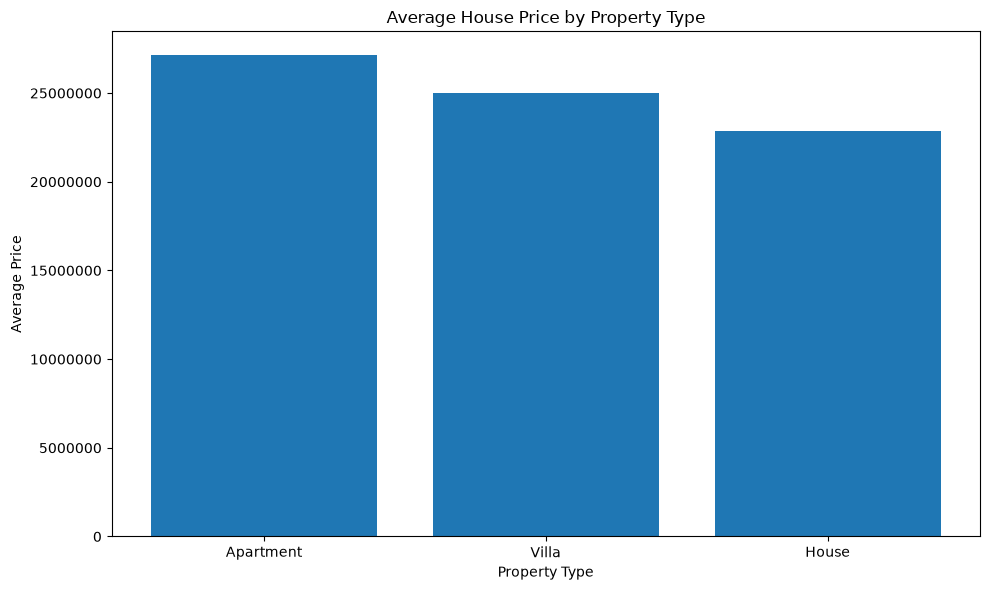

In [20]:
type_price = df.groupby("Property_Type")["Price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

plt.bar(
    type_price.index,
    type_price.values
)

plt.title("Average House Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\average_price_by_property_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

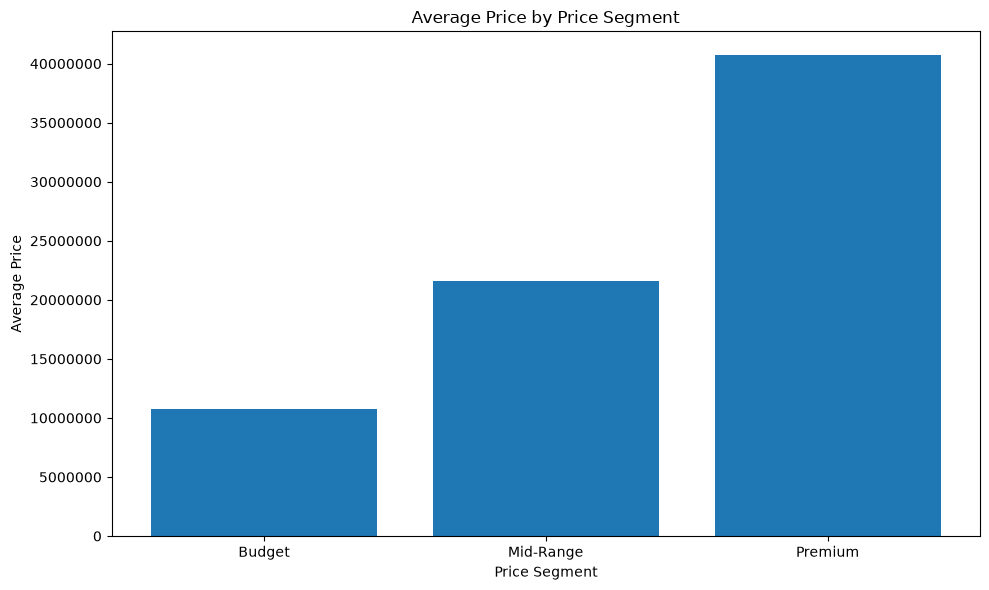

In [21]:
segment_price = df.groupby(
    "Price_Segment",
    observed=False
)["Price"].mean()

plt.figure(figsize=(10, 6))

plt.bar(
    segment_price.index.astype(str),
    segment_price.values
)

plt.title("Average Price by Price Segment")
plt.xlabel("Price Segment")
plt.ylabel("Average Price")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\average_price_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

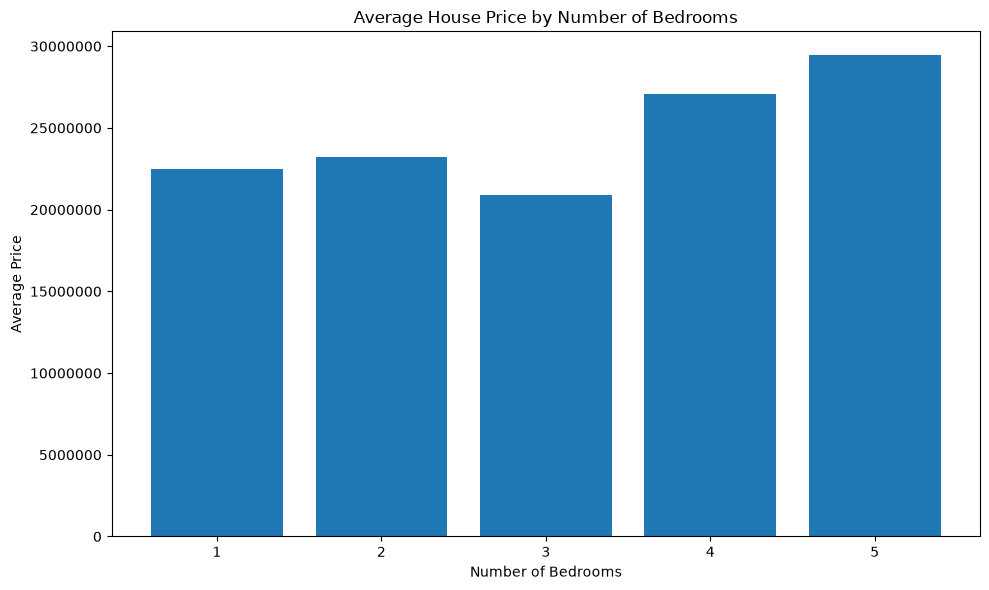

In [22]:
bedroom_price = df.groupby("Bedrooms")["Price"].mean()

plt.figure(figsize=(10, 6))

plt.bar(
    bedroom_price.index.astype(str),
    bedroom_price.values
)

plt.title("Average House Price by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average Price")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\average_price_by_bedrooms.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

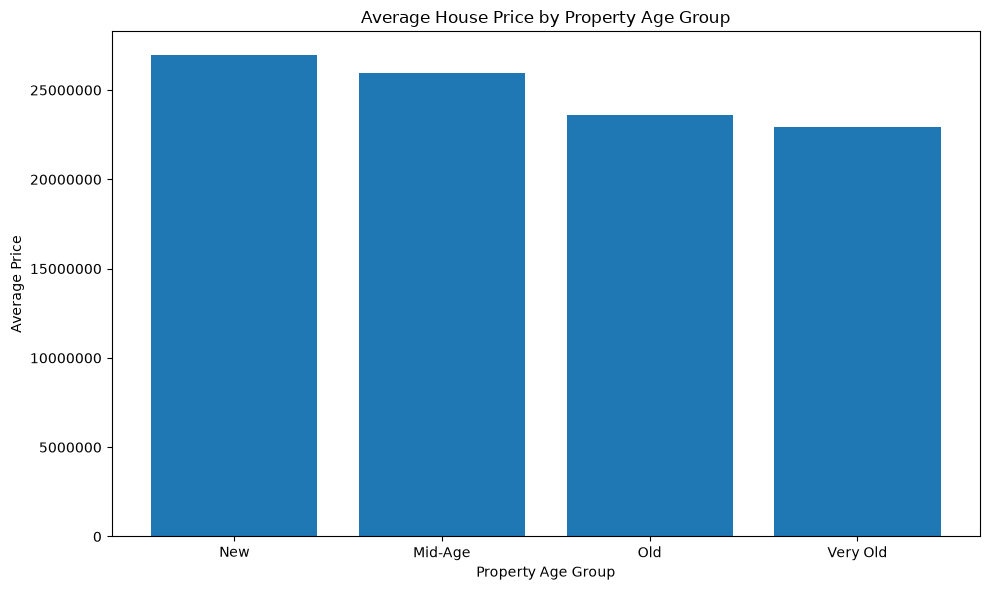

In [23]:
age_group_price = df.groupby(
    "Age_Group",
    observed=False
)["Price"].mean()

plt.figure(figsize=(10, 6))

plt.bar(
    age_group_price.index.astype(str),
    age_group_price.values
)

plt.title("Average House Price by Property Age Group")
plt.xlabel("Property Age Group")
plt.ylabel("Average Price")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\average_price_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Executive Summary

This House Price Analysis examines 300 properties to identify the major factors associated with property prices. The analysis covers property size, bedrooms, bathrooms, age, location, property type, price segments, and price per area.

### Key Findings

- The average property price is approximately ₹2.49 crore, with prices ranging from ₹36.95 lakh to ₹5.87 crore.
- Property area has the strongest numerical relationship with price, with a correlation of 0.796.
- City Center properties have the highest average price at approximately ₹3.31 crore, compared with ₹2.51 crore in Suburbs and ₹1.65 crore in Rural areas.
- Apartments have the highest average price among property types at approximately ₹2.71 crore.
- Premium properties have an average price of approximately ₹4.07 crore and an average area of approximately 3,952.
- Budget properties have an average price of approximately ₹1.07 crore and an average area of approximately 1,279.
- New properties have a higher average price than older properties, although the relationship between age and price is relatively weak.
- The average price per unit of area is approximately ₹9,542.84.

## Business Insights

### 1. Property Size Is a Major Pricing Factor
The strong positive correlation between area and price indicates that larger properties generally command higher prices.

### 2. Location Creates Significant Price Differences
City Center properties have substantially higher average prices than Suburban and Rural properties. Location should therefore be considered a major pricing and investment factor.

### 3. Premium Properties Offer Larger Spaces
Premium properties have substantially larger average areas than Budget properties, suggesting that property size is an important characteristic of the premium segment.

### 4. Rural Properties Can Offer Better Value per Area
The properties with the lowest price per area are concentrated in Rural locations, indicating potentially better space-for-price value for budget-conscious buyers.

### 5. Property Age Has a Smaller Influence
Newer properties generally have higher average prices, but the relatively weak correlation suggests that age alone is not a strong predictor of price.

## Business Recommendations

1. **Real estate sellers should prioritize property size and location when setting asking prices.**
2. **Buyers seeking premium locations should compare properties based on price per area rather than total price alone.**
3. **Budget-conscious buyers should consider Rural and Suburban properties for better space-to-price value.**
4. **Real estate companies can segment properties into Budget, Mid-Range, and Premium categories for targeted marketing.**
5. **Property valuation models should give greater weight to area and location while treating age as a secondary factor.**
6. **Real estate dashboards should track average price, median price, price per area, location, property type, and property age.**

> **Note:** This dataset is used for analytical and portfolio purposes. The relationships identified represent associations within this dataset and should not be interpreted as causal relationships.

## Data Dictionary

| Column | Description | Data Type |
|---|---|---|
| Property_ID | Unique identifier for each property | String |
| Area | Size of the property | Integer |
| Bedrooms | Number of bedrooms | Integer |
| Bathrooms | Number of bathrooms | Integer |
| Age | Age of the property in years | Integer |
| Location | Property location category | String |
| Property_Type | Type of property | String |
| Price | Total property price | Integer |
| Price_Segment | Budget, Mid-Range, or Premium category based on price | Categorical |
| Price_per_Area | Price divided by property area | Float |
| Age_Group | New, Mid-Age, Old, or Very Old category | Categorical |

## Data Quality & Validation

The dataset was validated before analysis to ensure reliability and consistency.

### Validation Results

| Check | Result |
|---|---:|
| Total records | 300 |
| Total columns | 11 |
| Missing values | 0 |
| Duplicate rows | 0 |
| Unique Property IDs | 300 |
| Negative/zero prices | 0 |
| Negative/zero area values | 0 |

### Validation Approach

- Checked the dataset shape and column structure.
- Verified missing values across all columns.
- Checked for duplicate records.
- Confirmed that each property has a unique `Property_ID`.
- Verified numerical variables such as `Area` and `Price`.
- Created derived variables only after validating the original dataset.
- Used descriptive statistics, grouping, and correlation analysis to identify patterns.

# Project 6 — House Price Analysis

## Project Overview

This project analyzes a dataset of 300 residential properties to identify the key factors associated with house prices. The analysis focuses on property size, bedrooms, bathrooms, age, location, property type, price segments, and price per area.

The project demonstrates practical data analysis using Python and pandas, supported by statistical analysis and data visualizations.

## Objectives

- Analyze the distribution of house prices.
- Identify relationships between property characteristics and price.
- Compare prices across different locations.
- Compare prices across property types.
- Segment properties into Budget, Mid-Range, and Premium categories.
- Analyze price differences based on number of bedrooms and property age.
- Calculate price per unit of area to identify potential value properties.
- Generate actionable business insights and recommendations.

## Dataset

The dataset contains 300 property records and 8 original columns.

### Original Columns

- `Property_ID`
- `Area`
- `Bedrooms`
- `Bathrooms`
- `Age`
- `Location`
- `Property_Type`
- `Price`

### Derived Columns

- `Price_Segment`
- `Price_per_Area`
- `Age_Group`

## Key Results

- Average property price: approximately **₹2.49 crore**
- Minimum property price: approximately **₹36.95 lakh**
- Maximum property price: approximately **₹5.87 crore**
- Area–Price correlation: **0.796**
- City Center average price: approximately **₹3.31 crore**
- Suburb average price: approximately **₹2.51 crore**
- Rural average price: approximately **₹1.65 crore**
- Apartment average price: approximately **₹2.71 crore**
- Premium properties average price: approximately **₹4.07 crore**
- Average price per area: approximately **₹9,542.84**

## Visualizations

1. House Price Distribution
2. Area vs House Price
3. Average House Price by Location
4. Average House Price by Property Type
5. Average Price by Price Segment
6. Average House Price by Number of Bedrooms
7. Average House Price by Property Age Group

## Business Insights

### Property Size

Property area has the strongest numerical relationship with price, with a correlation of **0.796**.

### Location

City Center properties have substantially higher average prices than Suburban and Rural properties.

### Property Type

Apartments have the highest average price among the three property types analyzed.

### Price Segmentation

Premium properties are considerably larger and more expensive than Budget properties.

### Value Analysis

Rural properties dominate the lowest price-per-area observations, suggesting potentially better space-for-price value.

### Property Age

Newer properties generally have higher average prices, although age has a relatively weak relationship with price compared with area and location.

## Business Recommendations

1. Real estate sellers should consider both property size and location when setting asking prices.
2. Buyers should compare price per area in addition to total property price.
3. Budget-conscious buyers can explore Rural and Suburban properties for potentially better space-to-price value.
4. Real estate companies can use price segmentation for targeted marketing.
5. Property valuation models should give greater importance to area and location.
6. Real estate dashboards should track price, area, location, property type, age, and price per area.

## Data Quality

- Records: **300**
- Missing values: **0**
- Duplicate rows: **0**
- Unique Property IDs: **300**
- Numerical variables were checked for valid values.
- Derived features were created from validated source data.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Project Structure

```text
06_house_price_analysis.ipynb
data/
└── house_prices (1).csv
visualizations/
├── house_price_distribution.png
├── area_vs_price.png
├── average_price_by_location.png
├── average_price_by_property_type.png
├── average_price_by_segment.png
├── average_price_by_bedrooms.png
└── average_price_by_age_group.png
## Conclusion

The analysis indicates that property area and location are the most important factors associated with house prices in this dataset. Price segmentation and price-per-area analysis provide additional perspectives for buyers, sellers, and real estate businesses.